# BOTA: анализ в одном ноутбуке
**Статья:** Machine Learning Methods for Causal Inference and Decision Analytics: Evidence from the BOTA Cash Transfer Experiment in Kazakhstan

**Как запустить:** положите 12 файлов `.dta` в папку `data` рядом с ноутбуком (список в ячейке 1) и выберите *Run all*. Полный прогон занимает около 4 минут (самая долгая часть — ячейка 9, лес на 21 разбиении × 2 набора признаков).

**Карта «элемент статьи → ячейка»**

| В статье | Что это | Ячейка |
|---|---|---|
| данные | сборка данных | раздел 3 |
| Fig. 1, tab_itt | эффект программы на еду (RQ1) | раздел 4, таблица и график — разделы 9–10 |
| tab_balance | баланс групп до программы | раздел 5, таблица — раздел 9 |
| tab_same, tab_secondary | та же выборка; другие траты | раздел 6, таблицы — раздел 9 |
| Fig. 2, tab_models (RQ2), Fig. 3, tab_alloc (RQ3) | модели на новых округах, выбор округов | разделы 7–8, таблицы — 9, графики — 10 |

In [13]:
# 1. Imports and data folder
import numpy as np, pandas as pd, json, os, glob
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option('display.width', 200)

DATA = 'data'   # folder with the .dta files (names as on the Microdata Library, without any prefix)
NEEDED = ['bl_hh_v2_2','bl_hh_v2_2_qg01','bl_hh_v2_2_qg06','bl_hh_v2_2_qg07','bl_hh_v2_2_qg08','bl_hhmem_v2_2',
          'fu_hh_v2_2','fu_hh_v2_2_qg01','fu_hh_v2_2_qg06','fu_hh_v2_2_qg07','fu_hh_v2_2_qg08','fu_hhmem_v2_2']
def rd(name):
    name = name if name.endswith('.dta') else name + '.dta'
    p = os.path.join(DATA, name)
    if not os.path.exists(p):
        m = glob.glob(os.path.join(DATA, '*' + name))
        if not m: raise FileNotFoundError(name + ' not found in ' + DATA)
        p = m[0]
    return pd.io.stata.StataReader(p).read(convert_categoricals=False)
print({f: any(os.path.exists(os.path.join(DATA, f + '.dta')) or glob.glob(os.path.join(DATA, '*' + f + '.dta')) for _ in [0]) for f in NEEDED})

{'bl_hh_v2_2': True, 'bl_hh_v2_2_qg01': True, 'bl_hh_v2_2_qg06': True, 'bl_hh_v2_2_qg07': True, 'bl_hh_v2_2_qg08': True, 'bl_hhmem_v2_2': True, 'fu_hh_v2_2': True, 'fu_hh_v2_2_qg01': True, 'fu_hh_v2_2_qg06': True, 'fu_hh_v2_2_qg07': True, 'fu_hh_v2_2_qg08': True, 'fu_hhmem_v2_2': True}


## 2. Вспомогательные функции
*Что это:* регрессия с весами и стандартными ошибками по округам (`wls_cr`), wild-bootstrap p-value (`wild_p`), собственный causal forest (`CausalForest`) и вспомогательные модели (`crossfit_m`, `rf_fit`).
*Что сказать:* стандартные ошибки считаются по **округам**, потому что программу назначали округам, а не семьям.

In [14]:
# 2. Helper functions

def wls(X,y,w):
    XtW=X.T*w; A=XtW@X; b=np.linalg.solve(A,XtW@y); return b,np.linalg.inv(A)
def wls_cr(X,y,w,g):
    """WLS with CR1 cluster-robust variance. returns beta, se, df"""
    b,Ainv=wls(X,y,w); e=y-X@b; s=X*(w*e)[:,None]
    ug,inv=np.unique(g,return_inverse=True); S=np.zeros((len(ug),X.shape[1])); np.add.at(S,inv,s)
    G=len(ug); N,K=X.shape; V=Ainv@(S.T@S)@Ainv*(G/(G-1))*((N-1)/(N-K))
    return b,np.sqrt(np.diag(V)),G-1
def wild_p(y,Z,w,g,B=1999,seed=1):
    """wild cluster bootstrap p-value for H0: tau=0 (Rademacher weights, null imposed)"""
    rng=np.random.RandomState(seed); X=np.column_stack([np.ones(len(y)),Z])
    b,se,_=wls_cr(X,y,w,g); t0=b[1]/se[1]
    a0=np.average(y,weights=w); e0=y-a0; ug,inv=np.unique(g,return_inverse=True); cnt=0
    for _ in range(B):
        v=rng.choice([-1.0,1.0],size=len(ug))[inv]; ys=a0+e0*v
        bb,ss,_=wls_cr(X,ys,w,g); cnt+= abs(bb[1]/ss[1])>=abs(t0)-1e-12
    return (cnt+1)/(B+1)

class CausalForest:
    """Honest causal forest in the spirit of Wager-Athey / GRF. Trees are grown on a gradient pseudo-outcome,
    leaf effects come from a separate half of the okrugs (honesty). Subsampling is by okrug."""
    def __init__(self,n_trees=1000,sub=0.5,max_depth=3,min_leaf=12,min_arm=3,seed=0):
        self.n_trees,self.sub,self.max_depth,self.min_leaf,self.min_arm,self.seed=n_trees,sub,max_depth,min_leaf,min_arm,seed
    def fit(self,X,ytil,wtil,w,g):
        rng=np.random.RandomState(self.seed); ug=np.unique(g); self.trees=[]
        idx_by={u:np.where(g==u)[0] for u in ug}
        for t in range(self.n_trees):
            ch=rng.choice(ug,size=max(4,int(round(self.sub*len(ug)))),replace=False); rng.shuffle(ch)
            A=np.concatenate([idx_by[u] for u in ch[:len(ch)//2]]); B=np.concatenate([idx_by[u] for u in ch[len(ch)//2:]])
            wa,za,ya=w[A],wtil[A],ytil[A]
            if (za>0).sum()<3 or (za<0).sum()<3: continue
            tauA=np.sum(wa*za*ya)/np.sum(wa*za*za); var=np.sum(wa*za*za)/np.sum(wa)
            rho=za*(ya-tauA*za)/var
            tr=DecisionTreeRegressor(max_depth=self.max_depth,min_samples_leaf=self.min_leaf,max_features=2,random_state=rng.randint(1<<30))
            tr.fit(X[A],rho,sample_weight=wa)
            lf=tr.apply(X[B]); leaf_tau={}
            for l in np.unique(lf):
                m=lf==l; zb=wtil[B][m]
                if (zb>0).sum()>=self.min_arm and (zb<0).sum()>=self.min_arm:
                    leaf_tau[l]=np.sum(w[B][m]*zb*ytil[B][m])/np.sum(w[B][m]*zb*zb)
            self.trees.append((tr,leaf_tau))
        return self
    def predict(self,X):
        S=np.zeros(len(X)); C=np.zeros(len(X))
        for tr,lt in self.trees:
            lf=tr.apply(X); v=np.array([lt.get(l,np.nan) for l in lf]); ok=~np.isnan(v)
            S[ok]+=v[ok]; C[ok]+=1
        return S/np.maximum(C,1)

def crossfit_m(X,y,w,g,folds=5,seed=0):
    """okrug-grouped cross-fitted outcome model m(x)=E[Y|X]"""
    rng=np.random.RandomState(seed); ug=np.unique(g); rng.shuffle(ug); f={u:i%folds for i,u in enumerate(ug)}; fi=np.array([f[x] for x in g]); m=np.zeros(len(y))
    for k in range(folds):
        tr=fi!=k; rf=RandomForestRegressor(200,min_samples_leaf=25,random_state=seed+k,n_jobs=-1).fit(X[tr],y[tr],sample_weight=w[tr]); m[~tr]=rf.predict(X[~tr])
    return m
def rf_fit(X,y,w,seed=0): return RandomForestRegressor(200,min_samples_leaf=25,random_state=seed,n_jobs=-1).fit(X,y,sample_weight=w)

## 3. Сборка данных (переменные)
*Что делает:* из файлов Stata считает результат Y (траты на еду на человека за 30 дней), признаки 2011 года (12 штук), округ (первые 7 цифр номера семьи) и общие расходы.
*Что сказать:* еда = позиции 1–73 за последние 7 дней × 30/7, делим на число постоянно живущих членов семьи. Алкоголь и сигареты (74–78) не входят.

In [15]:
# 3. Build the data
g=rd('fu_hh_v2_2_qg01')
# food = items 1..73 (items 74-78 are alcohol and cigarettes and are dropped)
g['food']=((g.qg01==1)&(g.item_qg01<=73)).astype(float)*g.qg04.fillna(0)
F=g.groupby('hh_id').agg(F7=('food','sum'),dk=('qg01',lambda s:(s==98).sum()))
F['n_items']=g[(g.qg01==1)&(g.item_qg01<=73)].groupby('hh_id').size()
F['n_items']=F.n_items.fillna(0)
# follow-up household size from roster (members who permanently live here)
fm=rd('fu_hhmem_v2_2')
n_fu=fm[fm.qa07a==1].groupby('hh_id').size().rename('n_fu')
fh=rd('fu_hh_v2_2')[['hh_id','areatype','wt_hh','quintile','raion','cluster']]
d=fh.merge(F,left_on='hh_id',right_index=True,how='left').merge(n_fu,left_on='hh_id',right_index=True,how='left')
d['okrug']=d.hh_id//1000
d['Z']=(d.areatype==1).astype(int)
d['Y']=30/7*d.F7/d.n_fu
# baseline
bm=rd('bl_hhmem_v2_2'); bh=rd('bl_hh_v2_2')[['hh_id','quintile','areatype','wt_hh']].rename(columns={'quintile':'q_b','areatype':'area_b','wt_hh':'wt_b'})
nb=bm[bm.qa07a==1].groupby('hh_id').size().rename('hhsize_b')
head=bm[(bm.qa07==1)].groupby('hh_id').qa19.first().rename('head_edu_b')
base=bh.merge(nb,left_on='hh_id',right_index=True,how='left').merge(head,left_on='hh_id',right_index=True,how='left')
base['okrug']=base.hh_id//1000; base['found_fu']=base.hh_id.isin(d.hh_id).astype(int)
d=d.merge(base[['hh_id','q_b','hhsize_b','head_edu_b']],on='hh_id',how='left')
d['linked']=d.hh_id.isin(base.hh_id).astype(int)
# ---- extra baseline covariates (chosen by meaning BEFORE looking at any result) ----
bg=rd('bl_hh_v2_2_qg01'); bg['food']=((bg.qg01==1)&(bg.item_qg01<=73)).astype(float)*bg.qg04.fillna(0)
fb=bg.groupby('hh_id').food.sum().rename('F7_b')
bhh=rd('bl_hh_v2_2')
hd=bm[bm.qa07==1].groupby('hh_id').agg(head_age_b=('qa05','first'),head_female_b=('qa04',lambda s:float(s.iloc[0]==2)))
u7=bm[(bm.qa07a==1)&(bm.qa05<=6)].groupby('hh_id').size().rename('n_u7_b')
ex=pd.DataFrame({'hh_id':bhh.hh_id,'debt_b':(bhh.qh44==1).astype(float).where(bhh.qh44!=98),
 'state_aid_b':(bhh.qh27==1).astype(float),'min_rayon_b':bhh.qf13a_1*60+bhh.qf13b_1,
 'sep_house_b':(bhh.qf02==3).astype(float).where(~bhh.qf02.isin([97,98])),'diet_prob_b':(bhh.qi01==2).astype(float)})
base=base.merge(fb,left_on='hh_id',right_index=True,how='left').merge(hd,left_on='hh_id',right_index=True,how='left').merge(u7,left_on='hh_id',right_index=True,how='left').merge(ex,on='hh_id',how='left')
base['n_u7_b']=base.n_u7_b.fillna(0); base['food_b']=30/7*base.F7_b/base.hhsize_b
XC=['F7_b','food_b','head_age_b','head_female_b','n_u7_b','debt_b','state_aid_b','min_rayon_b','sep_house_b','diet_prob_b']
d=d.merge(base[['hh_id']+XC],on='hh_id',how='left')

# ---- total consumption per person (30 days), both rounds; nominal tenge, per capita (no price deflation, no adult equivalents) ----
LUMPY8=[8,11]+list(range(13,25))+[26,29,31,32,45,46]   # durable goods, jewellery, vehicles, holiday, property tax (qg08)
LUMPY7=[5,7,8]                                          # medical equipment, renovation materials, legal/weddings/funeral (qg07)
def nonfood(f6,f7,f8):
    q6=rd(f6); q7=rd(f7); q8=rd(f8)
    a=q6.groupby('hh_id').qg06.sum()+q7.groupby('hh_id').qg07.sum()/3+q8.groupby('hh_id').qg08.sum()/12
    r=(q6.groupby('hh_id').qg06.sum()+q7[~q7.item_qg07.isin(LUMPY7)].groupby('hh_id').qg07.sum()/3+q8[~q8.item_qg08.isin(LUMPY8)].groupby('hh_id').qg08.sum()/12)
    return pd.DataFrame({'nf_all':a,'nf_reg':r})
nb_=nonfood('bl_hh_v2_2_qg06','bl_hh_v2_2_qg07','bl_hh_v2_2_qg08')
nf_=nonfood('fu_hh_v2_2_qg06','fu_hh_v2_2_qg07','fu_hh_v2_2_qg08')
base=base.merge(nb_,left_on='hh_id',right_index=True,how='left')
base['Tb_all']=base.food_b+base.nf_all/base.hhsize_b; base['Tb_reg']=base.food_b+base.nf_reg/base.hhsize_b
d=d.merge(nf_,left_on='hh_id',right_index=True,how='left').merge(base[['hh_id','Tb_all','Tb_reg']],on='hh_id',how='left')
d['T_all']=d.Y+d.nf_all/d.n_fu; d['T_reg']=d.Y+d.nf_reg/d.n_fu
print('total consumption pc, follow-up (all / regular):',d.T_all.mean().round(0),d.T_reg.mean().round(0),'| baseline:',base.Tb_all.mean().round(0),base.Tb_reg.mean().round(0))

# adult-equivalent size (OECD-modified scale as described in the data documentation: head 1, other adults 0.5, children 0.3;
# the age limit for "child" is not stated in the documentation, so we assume age < 14)
def ae_size(roster):
    p=roster[roster.qa07a==1]; n=p.groupby('hh_id').size(); ch=p[p.qa05<14].groupby('hh_id').size().reindex(n.index).fillna(0); ad=n-ch
    return (1+0.5*(ad-1)+0.3*ch).where(ad>=1).rename('n_ae')
aeb=ae_size(bm); aef=ae_size(fm)
base=base.merge(aeb,left_on='hh_id',right_index=True,how='left'); d=d.merge(aef,left_on='hh_id',right_index=True,how='left')
base['Tb_reg_ae']=base.Tb_reg*base.hhsize_b/base.n_ae; d['T_reg_ae']=d.T_reg*d.n_fu/d.n_ae; d=d.merge(base[['hh_id','Tb_reg_ae']],on='hh_id',how='left')
print('baseline food pc:',base.food_b.describe().round(0).to_dict(),'missing',base.food_b.isna().sum())
print('extra covariate missing (baseline hh):',base[XC].isna().sum()[lambda x:x>0].to_dict())

print('follow-up hh',len(d),'| missing Y',d.Y.isna().sum(),'| Y==0',(d.Y==0).sum(),'| dk hh',(d.dk>0).sum(),'| n_fu missing',d.n_fu.isna().sum())
print(d.Y.describe().round(0).to_dict())
L=d[d.linked==1]
print('linked',len(L),'missing hhsize_b',L.hhsize_b.isna().sum(),'missing head_edu_b',L.head_edu_b.isna().sum(),'missing q_b',L.q_b.isna().sum())
print('baseline hh',len(base),'found at follow-up',base.found_fu.sum(),'by arm',base.groupby('area_b').found_fu.agg(['sum','count']).to_dict())

total consumption pc, follow-up (all / regular): 18951.0 17126.0 | baseline: 18500.0 16878.0
baseline food pc: {'count': 1161.0, 'mean': 10498.0, 'std': 5976.0, 'min': 2000.0, '25%': 6667.0, '50%': 9086.0, '75%': 12857.0, 'max': 63188.0} missing 4
extra covariate missing (baseline hh): {'food_b': 4, 'debt_b': 2, 'sep_house_b': 21}
follow-up hh 2289 | missing Y 7 | Y==0 1 | dk hh 0 | n_fu missing 7
{'count': 2282.0, 'mean': 9807.0, 'std': 5200.0, 'min': 0.0, '25%': 6679.0, '50%': 8859.0, '75%': 11705.0, 'max': 102664.0}
linked 966 missing hhsize_b 3 missing head_edu_b 0 missing q_b 0
baseline hh 1165 found at follow-up 966 by arm {'sum': {1: 506, 2: 460}, 'count': {1: 585, 2: 580}}


## 4. RQ1: средний эффект программы на еду → Fig. 1 и tab_itt
*Что делает:* регрессия Y на «есть программа» (ITT) с весами и стандартными ошибками по округам, плюс проверки (без весов, без выбросов, с районами, на связанных семьях, с признаками, с весами связи).
*Что сказать:* оценка −561 тенге, 95% интервал от −1 329 до 207 включает ноль: статистически убедительного роста еды не обнаружено.

In [16]:
# 4. Samples and RQ1 (ITT)
R={}
# ---------- samples ----------
d=d[d.Y.notna()&d.n_fu.notna()].copy()           # drop 7 households without outcome
R['n_followup_all']=2289; R['n_missing_outcome']=2289-len(d)
R['SF']=dict(n=len(d),okrugs=int(d.okrug.nunique()),T=int(d.Z.sum()),C=int((1-d.Z).sum()))
cov=['hhsize_b','head_edu_b','q_b']
L=d[(d.linked==1)].copy(); R['n_linked_all']=len(L)
L=L.dropna(subset=cov).copy()
R['SL']=dict(n=len(L),okrugs=int(L.okrug.nunique()),T=int(L.Z.sum()),C=int((1-L.Z).sum()),dropped_cov=R['n_linked_all']-len(L))
R['link_share_baseline']=float(base.found_fu.mean()); R['link_share_followup']=len(d[d.linked==1])/len(d)
# ---------- RQ1: ITT ----------
def itt(df,y='Y',w='wt_hh',extra=None,fe=False):
    X=np.column_stack([np.ones(len(df)),df.Z.values]+([df[extra].values] if extra else []))
    if fe: X=np.column_stack([X,pd.get_dummies(df.raion,drop_first=True).values.astype(float)])
    b,se,dfree=wls_cr(X,df[y].values,df[w].values,df.okrug.values)
    tc=stats.t.ppf(.975,dfree); return dict(tau=float(b[1]),se=float(se[1]),lo=float(b[1]-tc*se[1]),hi=float(b[1]+tc*se[1]),p=float(2*(1-stats.t.cdf(abs(b[1]/se[1]),dfree))))
res={}
res['main']=itt(d)
res['main']['p_wild']=wild_p(d.Y.values,d.Z.values,d.wt_hh.values,d.okrug.values)
d['wt1']=1.0; res['unweighted']=itt(d,w='wt1')
lo,hi=d.Y.quantile([.01,.99]); d['Yw']=d.Y.clip(lo,hi); res['winsor']=itt(d,y='Yw')
res['raion_fe']=itt(d,fe=True)
ctrl=d[d.Z==0]; R['ctrl_mean']=float(np.average(ctrl.Y,weights=ctrl.wt_hh)); trt=d[d.Z==1]; R['trt_mean']=float(np.average(trt.Y,weights=trt.wt_hh))
R['ctrl_mean_unw']=float(ctrl.Y.mean())
res['SL_plain']=itt(L); Lc=L.copy(); 
for c in cov: Lc[c+'_s']=(Lc[c]-Lc[c].mean())/Lc[c].std()
res['SL_cov']=itt(Lc,extra=[c+'_s' for c in cov])

## 5. Связанные семьи и баланс групп до программы → tab_balance
*Что делает:* считает долю семей 2011 года, найденных в 2012 (в округах с программой и без), и сравнивает 12 признаков 2011 года между группами.
*Что сказать:* найдено 87% против 79% (p=0,010) — ограничение для RQ2 и RQ3. По еде в 2011 году группы различались (9 998 против 10 944 тенге, p=0,06).

In [17]:
# 5. Linkage and baseline balance
# linkage: attrition by arm (baseline households), selection on baseline covariates, IPW
bb=base.copy(); bb['Z']=(bb.area_b==1).astype(int); bb=bb.dropna(subset=cov)
Xb=np.column_stack([np.ones(len(bb)),bb.Z.values]); b,se,df_=wls_cr(Xb,bb.found_fu.values.astype(float),np.ones(len(bb)),bb.okrug.values)
R['link_rate']=dict(T=float(bb[bb.Z==1].found_fu.mean()),C=float(bb[bb.Z==0].found_fu.mean()),diff=float(b[1]),se=float(se[1]),p=float(2*(1-stats.t.cdf(abs(b[1]/se[1]),df_))))
sd={}
for c in cov:
    a=bb[bb.found_fu==1][c]; n=bb[bb.found_fu==0][c]; sd[c]=float((a.mean()-n.mean())/np.sqrt((a.var()+n.var())/2))
R['linked_vs_unlinked_std_diff']=sd
lr=LogisticRegression(C=1e6,max_iter=2000).fit(bb[['Z']+cov].values,bb.found_fu.values); bb['p_link']=lr.predict_proba(bb[['Z']+cov].values)[:,1]
Lc=Lc.merge(bb[['hh_id','p_link']],on='hh_id',how='left'); Lc['wt_ipw']=Lc.wt_hh/Lc.p_link
res['SL_ipw']=itt(Lc,w='wt_ipw')
Le=L.copy(); EXT_=['hhsize_b','head_edu_b','q_b','food_b','head_age_b','head_female_b','n_u7_b','debt_b','state_aid_b','min_rayon_b','sep_house_b','diet_prob_b']
for c in EXT_: Le[c]=Le[c].fillna(Le[c].median()); Le[c+'_s']=(Le[c]-Le[c].mean())/Le[c].std()
res['SL_food']=itt(Le,extra=['food_b_s']); res['SL_ext']=itt(Le,extra=[c+'_s' for c in EXT_]); R['itt']=res
# balance at baseline (all baseline households, weights wt_b, clustered by okrug)
bal={}
for c in EXT_:
    bz=base.dropna(subset=[c]).copy(); bz['Z']=(bz.area_b==1).astype(int)
    X=np.column_stack([np.ones(len(bz)),bz.Z.values]); b,se,df_=wls_cr(X,bz[c].values.astype(float),bz.wt_b.values,bz.okrug.values)
    sdp=float(np.sqrt((bz[bz.Z==1][c].var()+bz[bz.Z==0][c].var())/2))
    bal[c]=dict(n=len(bz),mean_C=float(b[0]),mean_T=float(b[0]+b[1]),diff=float(b[1]),std_diff=float(b[1]/sdp),p=float(2*(1-stats.t.cdf(abs(b[1]/se[1]),df_))))
R['balance']=bal

## 6. Одни и те же 960 семей: без поправки / с поправкой на 2011 / изменение; другие траты → tab_same и tab_secondary
*Что делает:* на тех же семьях считает эффект тремя способами, а на всех семьях — эффект на другие группы трат.
*Что сказать:* все интервалы включают ноль; общие расходы приближённые (номинальные тенге, свой список статей, на человека).

In [18]:
# 6. Same-sample comparison and other spending
def secondary(d0):
    d=d0[d0.Y.notna()&d0.n_fu.notna()].copy()
    q6=rd('fu_hh_v2_2_qg06')
    q7=rd('fu_hh_v2_2_qg07')
    q8=rd('fu_hh_v2_2_qg08')
    def grp(q,col,item,lo,hi,div,name): return (q[(q[item]>=lo)&(q[item]<=hi)].groupby('hh_id')[col].sum()/div).rename(name)
    S=pd.concat([grp(q8,'qg08','item_qg08',34,44,12,'educ'),grp(q8,'qg08','item_qg08',1,12,12,'clothes'),grp(q8,'qg08','item_qg08',13,33,12,'durables'),grp(q7,'qg07','item_qg07',1,5,3,'health')],axis=1).fillna(0)
    d=d.merge(S,left_on='hh_id',right_index=True,how='left').fillna({c:0 for c in S.columns})
    for c in ['educ','clothes','durables','health']: d[c+'_pc']=d[c]/d.n_fu
    def fit(df,y,extra=None):
        X=np.column_stack([np.ones(len(df)),df.Z.values]+([df[extra].values] if extra else []))
        b,se,f=wls_cr(X,df[y].values,df.wt_hh.values,df.okrug.values); t=stats.t.ppf(.975,f)
        c=df[df.Z==0]; return dict(tau=float(b[1]),se=float(se[1]),lo=float(b[1]-t*se[1]),hi=float(b[1]+t*se[1]),p=float(2*(1-stats.t.cdf(abs(b[1]/se[1]),f))),ctrl=float(np.average(c[y],weights=c.wt_hh)),n=int(len(df)))
    R={'full_sample':{y:fit(d,y) for y in ['Y','educ_pc','clothes_pc','durables_pc','health_pc','T_reg','T_all','T_reg_ae']}}
    # same sample S_L (the 960 linked households used for RQ2 and RQ3): all columns use exactly the same households
    L=d[(d.linked==1)].dropna(subset=['hhsize_b','head_edu_b','q_b','food_b','Tb_reg','Tb_all','Tb_reg_ae','T_reg','T_all','T_reg_ae']).copy()
    same={}
    for name,y,b in [('food','Y','food_b'),('total_reg','T_reg','Tb_reg'),('total_all','T_all','Tb_all'),('total_reg_ae','T_reg_ae','Tb_reg_ae')]:
        L['c_'+name]=L[y]-L[b]; L['bs_'+name]=(L[b]-L[b].mean())/L[b].std()
        same[name]=dict(unadjusted=fit(L,y),adjusted=fit(L,y,['bs_'+name]),change=fit(L,'c_'+name))
        # adjusted for baseline food as well (food-only baseline control for the total outcomes)
    same['total_reg_food_adj']=dict(unadjusted=fit(L,'T_reg'),adjusted=fit(L,'T_reg',['bs_food']),change=None)
    R['same_sample']=same; R['n_same_sample']=int(len(L))
    # baseline difference between arms in the same sample
    bal={}
    for k in ['food_b','Tb_reg']:
        bal[k]=fit(L.assign(**{'Z':L.Z}),k)
    R['baseline_diff_same_sample']=bal
    return R

S = secondary(d)
print('same-sample n =', S['n_same_sample'])

same-sample n = 960


## 7. RQ2 и RQ3: функция `run` (одно разбиение округов)
*Что делает:* делит 108 округов на 72 для обучения и 36 для проверки. На обучающих учатся три модели: постоянный эффект (M0), линейная с взаимодействиями (M1), causal forest (M2) (+ T-learner как проверка). На проверочных считается потеря R-loss, выигрыш над M0 и выигрыш правила «дать программу 18 округам с самым высоким прогнозом» над случайным выбором.
*Что сказать:* модель проверяется на округах, которых она не видела; при нуле в интервале пишем «преимущество не подтверждено», а не «преимущества нет».

In [19]:
# 7. One split of the okrugs: models, loss, allocation
# ---------- RQ2/RQ3 ----------
EXT=['hhsize_b','head_edu_b','q_b','food_b','head_age_b','head_female_b','n_u7_b','debt_b','state_aid_b','min_rayon_b','sep_house_b','diet_prob_b']
IMPUTE_N={c:int(L[c].isna().sum()) for c in EXT if L[c].isna().sum()>0}
for c in EXT: L[c]=L[c].fillna(L[c].median())
okr=L.groupby('okrug').Z.first().reset_index()
def split(seed):
    rng=np.random.RandomState(seed); dev=set()
    for a in [1,0]:
        ok=np.sort(okr[okr.Z==a].okrug.values); rng.shuffle(ok); dev|=set(ok[:36])
    return dev
def run(seed,Xcols,boot=False,B=1000):
    dev_ok=split(seed); isdev=L.okrug.isin(dev_ok).values; D=L[isdev]; E=L[~isdev]
    mu,sdv=D[Xcols].mean().values,D[Xcols].std().values
    XD=D[Xcols].values.astype(float); XE=E[Xcols].values.astype(float)
    yD,zD,wD,gD=D.Y.values,D.Z.values.astype(float),D.wt_hh.values,D.okrug.values
    yE,zE,wE,gE=E.Y.values,E.Z.values.astype(float),E.wt_hh.values,E.okrug.values
    e=0.5
    # nuisance
    mD=crossfit_m(XD,yD,wD,gD,seed=seed); mfull=rf_fit(XD,yD,wD,seed); mE=mfull.predict(XE)
    # M0 constant
    b0,_=wls(np.column_stack([np.ones(len(D)),zD]),yD,wD); tau0=b0[1]; t0=np.full(len(E),tau0)
    # M1 linear interaction
    sD=(XD-mu)/sdv; sE=(XE-mu)/sdv
    Xi=lambda s,z: np.column_stack([np.ones(len(z)),z,s,s*z[:,None]])
    b1,_=wls(Xi(sD,zD),yD,wD); t1=b1[1]+((sE)@b1[2+sD.shape[1]:])
    # M2 causal forest
    cf=CausalForest(n_trees=1000,seed=seed).fit(XD,yD-mD,zD-e,wD,gD); t2=cf.predict(XE)
    # outcome models for DR scores (fit on development set)
    f1=rf_fit(XD[zD==1],yD[zD==1],wD[zD==1],seed); f0=rf_fit(XD[zD==0],yD[zD==0],wD[zD==0],seed)
    mu1,mu0=f1.predict(XE),f0.predict(XE)
    Gam=mu1-mu0+zE*(yE-mu1)/e-(1-zE)*(yE-mu0)/(1-e)
    out=dict(seed=seed,n_dev=len(D),n_eval=len(E),T_dev=int(zD.sum()),C_dev=int((1-zD).sum()),T_eval=int(zE.sum()),C_eval=int((1-zE).sum()),tau0=float(tau0))
    ug,inv=np.unique(gE,return_inverse=True); nG=len(ug); den=np.bincount(inv,weights=wE,minlength=nG)
    preds={'M0':t0,'M1':t1,'M2':t2,'M3':mu1-mu0}; num={}
    for k,t in preds.items():
        r=((yE-mE)-(zE-e)*t)**2; num[k]=np.bincount(inv,weights=wE*r,minlength=nG); out['L_'+k]=float(num[k].sum()/den.sum())
    out['D_M1']=out['L_M0']-out['L_M1']; out['D_M2']=out['L_M0']-out['L_M2']; out['D_M3']=out['L_M0']-out['L_M3']
    a=np.bincount(inv,weights=wE*Gam,minlength=nG); tauDR=a.sum()/den.sum(); out['tauDR']=float(tauDR); out['V_rand']=float(.5*tauDR)
    ctrlE=E[E.Z==0]; out['ctrl_mean_eval']=float(np.average(ctrlE.Y,weights=ctrlE.wt_hh))
    pis={}
    for k in ['M1','M2']:
        sc=np.bincount(inv,weights=wE*preds[k],minlength=nG)/den; top=np.argsort(-sc)[:nG//2]; pi=np.zeros(nG); pi[top]=1; pis[k]=pi
        out['V_'+k]=float((pi*a).sum()/den.sum()); out['G_'+k]=out['V_'+k]-out['V_rand']
    # AUTOC and calibration slope
    def autoc(pred,gam,w):
        o=np.argsort(-pred); gw=(gam*w)[o]; ww=w[o]; cw=np.cumsum(ww)/ww.sum(); cg=np.cumsum(gw)/np.cumsum(ww); q=np.linspace(.01,1,100)
        toc=np.interp(q,cw,cg)-np.sum(gam*w)/w.sum(); return float(toc.mean())
    for k in ['M1','M2']: out['AUTOC_'+k]=autoc(preds[k],Gam,wE)
    Xc=np.column_stack([np.ones(len(E)),t2]); bc,sc_,dfc=wls_cr(Xc,Gam,wE,gE); out['calib_slope']=float(bc[1]); out['calib_se']=float(sc_[1])
    out['forest_imp']=None
    if boot:
        rng=np.random.RandomState(99); Ds={k:[] for k in ['D_M1','D_M2','G_M1','G_M2','AUTOC_M1','AUTOC_M2','tauDR','V_M2','V_M1','Vr']}
        idx_by=[np.where(inv==i)[0] for i in range(nG)]
        for _ in range(B):
            c=np.bincount(rng.randint(0,nG,nG),minlength=nG).astype(float); dn=(c*den).sum()
            Lb={k:(c*num[k]).sum()/dn for k in num}; Ds['D_M1'].append(Lb['M0']-Lb['M1']); Ds['D_M2'].append(Lb['M0']-Lb['M2'])
            tb=(c*a).sum()/dn; Ds['tauDR'].append(tb); Ds['Vr'].append(.5*tb)
            for k in ['M1','M2']:
                v=(c*pis[k]*a).sum()/dn; Ds['G_'+k].append(v-.5*tb); Ds['V_'+k].append(v)
            ii=np.concatenate([np.repeat(idx_by[i],int(c[i])) for i in range(nG) if c[i]>0])
            for k in ['M1','M2']: Ds['AUTOC_'+k].append(autoc(preds[k][ii],Gam[ii],wE[ii]))
        out['ci']={k:[float(np.percentile(v,2.5)),float(np.percentile(v,97.5))] for k,v in Ds.items()}
    # forest variable importance (share of splits weighted by depth) for description
    imp=np.zeros(len(Xcols))
    for tr,_ in cf.trees: imp+=tr.feature_importances_
    out['forest_imp']=(imp/imp.sum()).tolist(); out['t2_sd']=float(t2.std()); out['t1_sd']=float(t1.std())
    return out

## 8. Запуск: основное разбиение (seed 2026, с bootstrap) и 20 повторных
Для двух наборов признаков: **ext** (12 признаков, основной) и **base3** (первые 3). Самая долгая ячейка (около 4 минут).

In [20]:
# 8. Run: main split (with bootstrap) + 20 repeated splits, for 12 covariates (ext) and 3 covariates (base3)
def summ(reps, k): v=np.array([r[k] for r in reps]); return dict(median=float(np.median(v)),min=float(v.min()),max=float(v.max()),share_pos=float((v>0).mean()))
RES = {}
for name, cols in [('ext', EXT), ('base3', cov)]:
    main_ = run(2026, cols, boot=True)
    reps_ = [run(s, cols) for s in range(1, 21)]
    RES[name] = dict(main_split=main_, reps=reps_, rep_summary={k: summ(reps_, k) for k in ['D_M1','D_M2','D_M3','G_M1','G_M2','AUTOC_M2','calib_slope']})
    print(name, 'done')
E_ = dict(R); E_.update(RES['ext'])     # main results (12 covariates)
B_ = dict(R); B_.update(RES['base3'])   # comparison (3 covariates)

ext done
base3 done


## 9. Таблицы статьи (tab_itt, tab_balance, tab_same, tab_secondary, tab_models, tab_alloc)
Выводятся прямо в ноутбук. Числа берутся из ячеек выше, вручную ничего не вставляется.

In [21]:
# 9. Tables
import re
M='−'
def n(x,d=0):
    s=f"{abs(x):,.{d}f}"; return (M if x<0 and round(abs(x),d)>0 else '')+s
def ci(l,h,d=0): return f"[{n(l,d)}, {n(h,d)}]"
TABLES={}
def save(name,cap,label,cols,rows,note='',fs=None):
    df=pd.DataFrame(rows[1:],columns=rows[0]); TABLES[name]=df
    print('\n'+label.replace('tab:','Table: ')+' — '+cap.replace('$^2$','^2')); display(df); print(re.sub(r'\$','',note))
# ---- ITT
I=E_['itt']; m=I['main']
save('tab_itt','Effect of Access to BOTA on Food Consumption','tab:itt','lr',[['Quantity','Value'],['Control-group mean',n(E_['ctrl_mean'])],['Access-group mean',n(E_['trt_mean'])],
 ['Estimated effect (ITT)',n(m['tau'])],['95% interval',ci(m['lo'],m['hi'])],['Effect relative to control mean',f"{m['tau']/E_['ctrl_mean']*100:.1f}%".replace('-',M)],
 ['Clustered p / wild bootstrap p',f"{m['p']:.3f} / {m['p_wild']:.3f}"],['Households / okrugs',f"{E_['SF']['n']:,} / {E_['SF']['okrugs']}"]],
 'Units: tenge per person for a 30-day period, except the percentage and the $p$-values.','footnotesize')
# ---- balance
lab={'hhsize_b':'Household size','head_edu_b':'Head education (1--9)','q_b':'Welfare quintile (1--5)','food_b':'Food per person (tenge)','head_age_b':'Head age (years)','head_female_b':'Head is female','n_u7_b':'Children aged 0--6','debt_b':'Has debt','state_aid_b':'Gets state aid','min_rayon_b':'Minutes to rayon centre','sep_house_b':'Separate house','diet_prob_b':'Diet problems'}
rows=[['Variable (2011)','Control','Access','Std. diff.','p']]
for k,v in E_['balance'].items():
    d=0 if abs(v['mean_C'])>100 else (1 if abs(v['mean_C'])>5 else 2)
    rows.append([lab[k].replace('--','-'),n(v['mean_C'],d),n(v['mean_T'],d),(('+' if v['std_diff']>=0 else M)+f"{abs(v['std_diff']):.2f}"),f"{v['p']:.2f}"])
save('tab_balance','Baseline Characteristics by Arm (2011, All Baseline Households)','tab:balance','lrrrr',rows,'Weighted means. $p$-values from regressions clustered by okrug.')
# ---- other spending, full follow-up sample
F=S['full_sample']
nm=[('Y','Food (73 items)'),('educ_pc','Education'),('clothes_pc','Clothing and textiles'),('durables_pc','Durables and vehicles'),('health_pc','Health'),('T_reg','Total (approx.)'),('T_all','Total (all items)'),('T_reg_ae','Total (adult eq.)')]
rows=[['Spending group','Control mean','Effect [95% CI]','p']]+[[v,n(F[k]['ctrl']),f"{n(F[k]['tau'])} {ci(F[k]['lo'],F[k]['hi'])}",f"{F[k]['p']:.2f}"] for k,v in nm]
save('tab_secondary','Effect of Access on Other Spending (Tenge per Person for 30 Days)','tab:secondary','lrcr',rows,'Exploratory. 2,282 households, 108 okrugs. Total (approx.) is our approximation of the official aggregate (see text); the last row is per adult equivalent. Groups and aggregates are our own constructions from the consumption modules.')
# ---- same-sample comparison
SS=S['same_sample']
nm=[('food','Food'),('total_reg','Total (approx.)'),('total_all','Total (all items)'),('total_reg_ae','Total (adult eq.)')]
rows=[['Outcome','Unadjusted','Adjusted','Change score']]
for k,v in nm: rows.append([v]+[f"{n(SS[k][a]['tau'])} ({n(SS[k][a]['se'])})" for a in ['unadjusted','adjusted','change']])
save('tab_same','Estimates on the Same 960 Linked Households (Tenge)','tab:same','lccc',rows,f"Effect of access, estimate (clustered SE). Adjusted: baseline level of the same outcome (standardised) added as a covariate. Change score: 2012 minus 2011 value. The sample is identical in all cells.")
# ---- models and allocation
def stats_(R,k,s): v=np.array([r[k] for r in R['reps']])/s; return float(np.median(v)),float(v.min()),float(v.max()),int((v>0).sum())
def mrow(name,R,k,s=1e6,d=2,ciok=True):
    mm=R['main_split']; md,lo,hi,w=stats_(R,k,s); c=ci(*[x/s for x in mm['ci'][k]],d) if ciok and k in mm['ci'] else '--'
    return [name,f"{n(mm[k]/s,d)} {c}",f"{n(md,d)} {ci(lo,hi,d)}",f"{w}/20"]
hdr=['Model','Main split [95% CI]','Median [range]','Wins']
rows=[hdr,mrow('Linear, 12 cov.',E_,'D_M1'),mrow('Forest, 12 cov.',E_,'D_M2'),mrow('T-learner, 12 cov.',E_,'D_M3',ciok=False),mrow('Linear, 3 cov.',B_,'D_M1'),mrow('Forest, 3 cov.',B_,'D_M2')]
save('tab_models','Gain over the Constant-Effect Model (Million Tenge$^2$)','tab:models','lcll',rows,f"The R-loss of the constant-effect model on the main split is {E_['main_split']['L_M0']/1e6:.2f} (12 cov.) and {B_['main_split']['L_M0']/1e6:.2f} (3 cov.). A positive gain means a better model. Median, range and wins (splits with gain above zero) are over 20 other random splits.")
rows=[['Rule']+hdr[1:],mrow('Linear, 12 cov.',E_,'G_M1',1,0),mrow('Forest, 12 cov.',E_,'G_M2',1,0),mrow('Linear, 3 cov.',B_,'G_M1',1,0),mrow('Forest, 3 cov.',B_,'G_M2',1,0)]
save('tab_alloc','Gain of Allocation by Predicted Effects over Random Allocation (Tenge per Person)','tab:alloc','lcll',rows,'Each rule gives access to 18 of the 36 evaluation okrugs. Median, range and wins (splits with gain above zero) are over 20 other random splits.')


Table: itt — Effect of Access to BOTA on Food Consumption


,Quantity,Value
0,Control-group mean,"9,976"
1,Access-group mean,"9,415"
2,Estimated effect (ITT),−561
3,95% interval,"[−1,329, 207]"
4,Effect relative to control mean,−5.6%
5,Clustered p / wild bootstrap p,0.150 / 0.167
6,Households / okrugs,"2,282 / 108"


Units: tenge per person for a 30-day period, except the percentage and the p-values.

Table: balance — Baseline Characteristics by Arm (2011, All Baseline Households)


,Variable (2011),Control,Access,Std. diff.,p
0,Household size,6.1,6.2,+0.06,0.46
1,Head education (1-9),4.95,5.19,+0.18,0.02
2,Welfare quintile (1-5),3.04,2.96,−0.06,0.49
3,Food per person (tenge),"10,944","9,998",−0.16,0.06
4,Head age (years),47.9,46.3,−0.11,0.25
5,Head is female,0.19,0.18,−0.01,0.85
6,Children aged 0-6,1.95,2.00,+0.05,0.43
7,Has debt,0.48,0.56,+0.17,0.03
8,Gets state aid,0.64,0.65,+0.02,0.81
9,Minutes to rayon centre,52.4,46.8,−0.13,0.26


Weighted means. p-values from regressions clustered by okrug.

Table: secondary — Effect of Access on Other Spending (Tenge per Person for 30 Days)


,Spending group,Control mean,Effect [95% CI],p
0,Food (73 items),"9,976","−561 [−1,329, 207]",0.15
1,Education,777,"−17 [−152, 119]",0.81
2,Clothing and textiles,"1,478","−41 [−198, 116]",0.60
3,Durables and vehicles,551,"−83 [−230, 63]",0.26
4,Health,678,"−36 [−259, 188]",0.75
5,Total (approx.),"17,249","−776 [−2,264, 712]",0.30
6,Total (all items),"19,087","−888 [−2,693, 917]",0.33
7,Total (adult eq.),"34,176","−1,355 [−4,248, 1,537]",0.36


... (3 outputs left out)

,Model,Main split [95% CI],Median [range],Wins
0,"Linear, 12 cov.","−0.33 [−0.84, 0.15]","−0.30 [−0.99, 0.17]",1/20
1,"Forest, 12 cov.","−0.09 [−0.18, 0.01]","−0.05 [−0.49, 0.21]",9/20
2,"T-learner, 12 cov.",−0.11 --,"−0.27 [−0.95, 0.33]",4/20
3,"Linear, 3 cov.","−0.05 [−0.40, 0.25]","−0.13 [−0.50, 0.25]",6/20
4,"Forest, 3 cov.","−0.11 [−0.36, 0.13]","−0.08 [−0.44, 0.19]",6/20


The R-loss of the constant-effect model on the main split is 17.54 (12 cov.) and 16.85 (3 cov.). A positive gain means a better model. Median, range and wins (splits with gain above zero) are over 20 other random splits.

Table: alloc — Gain of Allocation by Predicted Effects over Random Allocation (Tenge per Person)


,Rule,Main split [95% CI],Median [range],Wins
0,"Linear, 12 cov.","−6 [−635, 561]","77 [−430, 611]",12/20
1,"Forest, 12 cov.","−222 [−852, 416]","−172 [−707, 413]",6/20
2,"Linear, 3 cov.","150 [−496, 781]","−83 [−595, 525]",8/20
3,"Forest, 3 cov.","−339 [−945, 265]","−235 [−819, 347]",5/20


Each rule gives access to 18 of the 36 evaluation okrugs. Median, range and wins (splits with gain above zero) are over 20 other random splits.


## 10. Графики статьи (Fig. 1, 2, 3)
- **Fig. 1:** эффект программы на еду во всех вариантах расчёта (точка — оценка, линия — 95% интервал, пунктир — ноль).
- **Fig. 2:** выигрыш моделей над моделью с постоянным эффектом (серые точки — 20 разбиений, чёрная черта — медиана, круг — основное разбиение; правее нуля = лучше).
- **Fig. 3:** то же для выбора округов по прогнозу против случайного выбора.

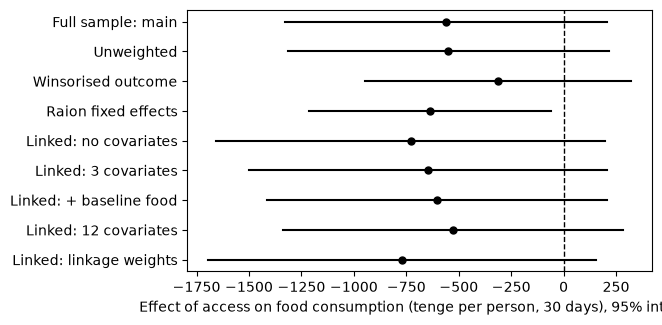

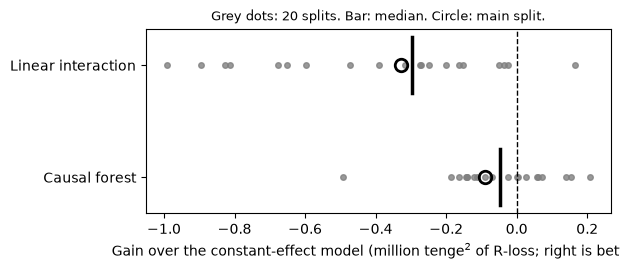

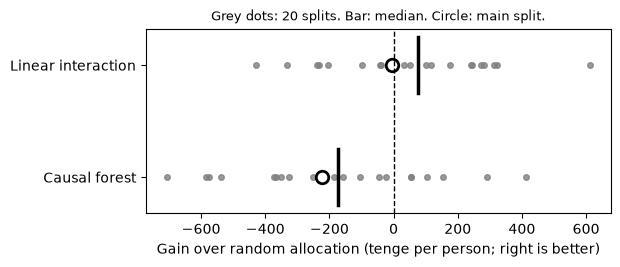

In [22]:
# 10. Figures
reps = E_['reps']; main = E_['main_split']
# Fig 1: ITT across specifications
rows=[('Full sample: main','main'),('Unweighted','unweighted'),('Winsorised outcome','winsor'),('Raion fixed effects','raion_fe'),('Linked: no covariates','SL_plain'),('Linked: 3 covariates','SL_cov'),('Linked: + baseline food','SL_food'),('Linked: 12 covariates','SL_ext'),('Linked: linkage weights','SL_ipw')]
fig,ax=plt.subplots(figsize=(6,3.4))
for i,(lab,k) in enumerate(rows):
    r=E_['itt'][k]; y=len(rows)-1-i; ax.plot([r['lo'],r['hi']],[y,y],'k-',lw=1.5); ax.plot(r['tau'],y,'ko',ms=5)
ax.axvline(0,ls='--',c='k',lw=1); ax.set_yticks(range(len(rows))); ax.set_yticklabels([l for l,_ in rows][::-1]); ax.set_xlabel('Effect of access on food consumption (tenge per person, 30 days), 95% interval')
plt.show()
def strip(keys,xlabel,unit,name,title):
    fig,ax=plt.subplots(figsize=(6,2.4))
    for j,(lab,k) in enumerate(keys):
        y=len(keys)-1-j; v=np.array([r[k] for r in reps])/unit; ax.plot(v,np.full(len(v),y),'o',c='gray',ms=4,alpha=.8); ax.plot([np.median(v)]*2,[y-.25,y+.25],'k-',lw=2.5)
        ax.plot(main[k]/unit,y,'o',mfc='none',mec='k',ms=9,mew=2)
    ax.axvline(0,ls='--',c='k',lw=1); ax.set_yticks(range(len(keys))); ax.set_yticklabels([l for l,_ in keys][::-1]); ax.set_xlabel(xlabel); ax.set_title(title,fontsize=9)
    plt.show()
strip([('Linear interaction','D_M1'),('Causal forest','D_M2')],'Gain over the constant-effect model (million tenge$^2$ of R-loss; right is better)',1e6,'fig_gain','Grey dots: 20 splits. Bar: median. Circle: main split.')
strip([('Linear interaction','G_M1'),('Causal forest','G_M2')],'Gain over random allocation (tenge per person; right is better)',1.0,'fig_alloc','Grey dots: 20 splits. Bar: median. Circle: main split.')

## 11. Контроль: ключевые числа (сверьте со статьёй)

In [23]:
# 11. Key numbers (compare with the paper)
m = E_['main_split']; I = E_['itt']
print('ITT main: %.0f [%.0f, %.0f], p=%.3f' % (I['main']['tau'], I['main']['lo'], I['main']['hi'], I['main']['p']))
print('Same sample (n=%d), food:' % S['n_same_sample'], {a: round(S['same_sample']['food'][a]['tau']) for a in ['unadjusted','adjusted','change']})
print('Forest rule gain over random, main split:', round(m['G_M2']))
print('Forest calibration slope: %.2f' % m['calib_slope'])

ITT main: -561 [-1329, 207], p=0.150
Same sample (n=960), food: {'unadjusted': -729, 'adjusted': -603, 'change': -262}
Forest rule gain over random, main split: -222
Forest calibration slope: -3.68


## 12. (по желанию) Сохранить все таблицы в один Excel-файл

In [24]:
# 12. Optional: all tables in one Excel file
try:
    with pd.ExcelWriter('bota_tables.xlsx') as w:
        for k, df in TABLES.items(): df.to_excel(w, sheet_name=k[:30], index=False)
    print('saved bota_tables.xlsx')
except Exception as e:
    print('Excel not available:', e)

saved bota_tables.xlsx


## Шпаргалка для защиты
- **«Откуда −561?»** Ячейка 4: `itt(d)` — взвешенная регрессия еды на признак «округ с программой», ошибки по округам.
- **«Почему не по семьям?»** Доступ давали округам: независимых единиц 108, а не 2 282.
- **«Как проверяли модель?»** Ячейки 7–8: обучение на 72 округах, проверка на 36 новых, так 21 раз.
- **«Что значит интервал с нулём?»** Данные не позволяют ни подтвердить рост, ни исключить его; это не доказательство нулевого эффекта.
- **«Почему только еда?»** Это основной результат; другие траты (ячейка 6) — исследовательские.
- **«Чем плох ваш лес?»** Он собственный, не настраивался и не сравнивался с независимой реализацией (grf/econml); проверялся только на искусственных данных.